In [ ]:
!pip install datasets sentence-transformers transformers scikit-learn tensorflow pandas numpy spacy
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 76.9 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# initialization of packages

import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.model_selection import train_test_split



1. Data Ingestion and Cleaning Scripts.
*  Ingest facehuggerapoorv/resume-jd-match.
*  Sanitization and token normalization.

In [ ]:
# Load dataset from Hugging Face
dataset = load_dataset("facehuggerapoorv/resume-jd-match")
df_train = pd.DataFrame(dataset['train'])
df_test = pd.DataFrame(dataset['test'])

# Combine train and test datasets
df = pd.concat([df_train, df_test], ignore_index=True)
df.info()
df.head()



README.md:   0%|          | 0.00/411 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 29.0MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 8.07MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/6241 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1759 [00:00<?, ? examples/s]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    8000 non-null   object
 1   label   8000 non-null   object
dtypes: object(2)
memory usage: 125.1+ KB


,text,label
0,For the given job description <<Net2Source Inc...,No Fit
1,For the given job description <<At Salas OBrie...,No Fit
2,For the given job description <<Schweitzer Eng...,No Fit
3,For the given job description <<Mizick Miller ...,No Fit
4,For the given job description <<Life at Capgem...,No Fit


In [ ]:
df['text'][0]

"For the given job description <<Net2Source Inc. is an award-winning total workforce solutions company recognized by Staffing Industry Analysts for our accelerated growth of 300% in the last 3 years with over 5500+ employees globally, with over 30+ locations in the US and global operations in 32 countries. We believe in providing staffing solutions to address the current talent gap  Right Talent  Right Time  Right Place  Right Price and acting as a Career Coach to our consultants.  \nRole: Basel Business AnalystLocation: Washington, D.C.Work Mode: HybridHire Type: 6+ Month Contract (extendable)\nJD: Role Specific Experience: 6+ years of relevant technical and business work experience The Candidates who have worked on Basel related projects in Credit risks or at least are aware of credit risk.  Banking & Financial domain experience, along with knowledge of risk management, familiarity with concepts of finance and accounting  Proficiency in MS Excel  Experience in defining and implementi

In [ ]:
def extract_jd_and_resume(row):
    text = row['text']
    # Extract text inside << >> following "For the given job description "
    jd_match = re.search(r'For the given job description\s*<<([\s\S]*?)>>', text)
    # Extract text inside << >> following "the resume: " or similar pattern
    resume_match = re.search(r'the resume:\s*<<([\s\S]*?)>>', text)

    jd = jd_match.group(1).strip() if jd_match else None
    resume = resume_match.group(1).strip() if resume_match else None
    return pd.Series([jd, resume])

# Apply extraction to populate the new columns
df[['job_description', 'resume_text']] = df.apply(extract_jd_and_resume, axis=1)

# Display summary and a preview of extracted columns
print(df[['job_description', 'resume_text']].isnull().sum())
display(df[['job_description', 'resume_text']].head())

job_description    0
resume_text        0
dtype: int64


,job_description,resume_text
0,Net2Source Inc. is an award-winning total work...,SummaryHighly motivated Sales Associate with e...
1,At Salas OBrien we tell our clients that were ...,Professional SummaryCurrently working with Cat...
2,Schweitzer Engineering Laboratories (SEL) Infr...,SummaryI started my construction career in Jun...
3,"Mizick Miller & Company, Inc. is looking for a...",SummaryCertified Electrical Foremanwith thirte...
4,Life at Capgemini\nCapgemini supports all aspe...,SummaryWith extensive experience in business/r...


In [ ]:
df['job_description'][0]
#df['resume_text'][0]
#df.head(1)

#df_temp = df
#df = df_temp
#df_temp.head(1)

"Net2Source Inc. is an award-winning total workforce solutions company recognized by Staffing Industry Analysts for our accelerated growth of 300% in the last 3 years with over 5500+ employees globally, with over 30+ locations in the US and global operations in 32 countries. We believe in providing staffing solutions to address the current talent gap  Right Talent  Right Time  Right Place  Right Price and acting as a Career Coach to our consultants.  \nRole: Basel Business AnalystLocation: Washington, D.C.Work Mode: HybridHire Type: 6+ Month Contract (extendable)\nJD: Role Specific Experience: 6+ years of relevant technical and business work experience The Candidates who have worked on Basel related projects in Credit risks or at least are aware of credit risk.  Banking & Financial domain experience, along with knowledge of risk management, familiarity with concepts of finance and accounting  Proficiency in MS Excel  Experience in defining and implementing technology solutions for a ma

2.Exploratory Data Analysis (EDA):

Check text length distributions for resumes and JDs.Compute label class distributions to verify balance.Identify missing values, non-English text entries, and noise artifacts.

--- Missing Values Check ---
text               0
label              0
job_description    0
resume_text        0
dtype: int64

--- Duplicate Check ---
Duplicate resume-JD pairs: 7

--- Class Distribution ---
label
No Fit           0.50
Potential Fit    0.25
Good Fit         0.25
Name: proportion, dtype: float64
--- Text Length Summary Statistics ---
       resume_word_count  jd_word_count
count        8000.000000    8000.000000
mean          704.394250     378.439875
std           387.030709     249.874677
min            84.000000      11.000000
25%           488.000000     169.000000
50%           618.000000     326.000000
75%           809.000000     552.000000
max          3134.000000    1254.000000


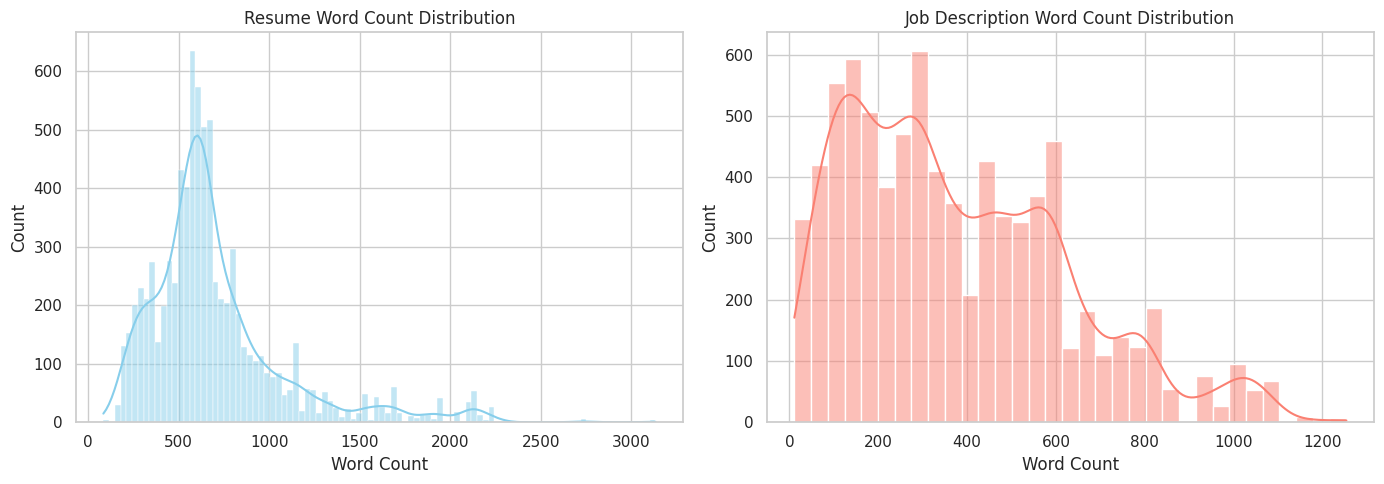

In [ ]:
#dataset exploratory data analysis (EDA)
# Cell 3: Data Cleanliness & Missing Value Inspection
print("--- Missing Values Check ---")
print(df.isnull().sum())

print("\n--- Duplicate Check ---")
print(f"Duplicate resume-JD pairs: {df.duplicated(subset=['resume_text', 'job_description']).sum()}")

# Target Label Distribution
print("\n--- Class Distribution ---")
if "label" in df.columns:
    print(df["label"].value_counts(normalize=True))


# Cell 4: Text Length Distribution & Quality Checks
df["resume_char_len"] = df["resume_text"].astype(str).apply(len)
df["jd_char_len"] = df["job_description"].astype(str).apply(len)

df["resume_word_count"] = df["resume_text"].astype(str).apply(lambda x: len(x.split()))
df["jd_word_count"] = df["job_description"].astype(str).apply(lambda x: len(x.split()))

print("--- Text Length Summary Statistics ---")
print(df[["resume_word_count", "jd_word_count"]].describe())


# Visualization configurations
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["resume_word_count"], kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Resume Word Count Distribution")
axes[0].set_xlabel("Word Count")

sns.histplot(df["jd_word_count"], kde=True, ax=axes[1], color="salmon")
axes[1].set_title("Job Description Word Count Distribution")
axes[1].set_xlabel("Word Count")

plt.tight_layout()
plt.show()


In [ ]:
#clean text data to clean the text
def clean_text(text: str) -> str:
    """Standardizes raw resume and JD text content."""
    if not isinstance(text, str):
        return ""
    # Strip HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)
    # Remove special characters while preserving punctuation useful for sentences
    text = re.sub(r'[^\w\s\.\,\+\#\-]', ' ', text)
    # Replace multiple spaces/newlines with single space and lower case
    #text = re.sub(r'\s+', ' ', text).strip()
    text = re.sub(r"\s+", " ", text).strip().lower()
    return text

# Standardize column naming
# Expected fields: 'resume_text', 'job_description', 'label'
df['clean_resume'] = df['resume_text'].apply(clean_text)
df['clean_jd'] = df['job_description'].apply(clean_text)


In [ ]:
df['clean_jd'][0]

'net2source inc. is an award-winning total workforce solutions company recognized by staffing industry analysts for our accelerated growth of 300 in the last 3 years with over 5500+ employees globally, with over 30+ locations in the us and global operations in 32 countries. we believe in providing staffing solutions to address the current talent gap right talent right time right place right price and acting as a career coach to our consultants. role basel business analystlocation washington, d.c.work mode hybridhire type 6+ month contract extendable jd role specific experience 6+ years of relevant technical and business work experience the candidates who have worked on basel related projects in credit risks or at least are aware of credit risk. banking financial domain experience, along with knowledge of risk management, familiarity with concepts of finance and accounting proficiency in ms excel experience in defining and implementing technology solutions for a major financial institut

In [ ]:
# Ensure numeric multi-class labels (0: Low, 1: Moderate, 2: High)
if df["label"].dtype == object:
    label_map = {"No Fit": 0, "Potential Fit": 1, "Good Fit": 2}
    df["target"] = df["label"].map(label_map).fillna(0).astype(int)
else:
    df["target"] = df["label"].astype(int)

In [ ]:
# Target Label Distribution
print("\n--- Class Distribution ---")
if "target" in df.columns:
    print(df["target"].value_counts(normalize=True))


--- Class Distribution ---
target
0    0.50
1    0.25
2    0.25
Name: proportion, dtype: float64


In [ ]:
df.columns

Index(['text', 'label', 'job_description', 'resume_text', 'resume_char_len',
       'jd_char_len', 'resume_word_count', 'jd_word_count', 'clean_resume',
       'clean_jd', 'target'],
      dtype='object')

In [ ]:
# Train / Validation / Test Split (70% Train, 15% Val, 15% Test)
train_df, df_temp = train_test_split(df, test_size=0.30, random_state=42, stratify=df['label'])
val_df, test_df = train_test_split(df_temp, test_size=0.50, random_state=42, stratify=df_temp['label'])



In [ ]:
# shape of datasets like train_df, val_df, test_df
train_df.shape, val_df.shape, test_df.shape

((5600, 11), (1200, 11), (1200, 11))

3.1 Stage 1: Baseline Model (TF-IDF + Cosine Similarity)
*  Goal: Establish a benchmark for term overlap without contextual semantics.
*  Mechanism: Calculate TF-IDF vectors over a shared vocabulary, taking cosine similarity between $\mathbf{v}_{\text{resume}}$ and $\mathbf{v}_{\text{jd}}$.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, f1_score, ndcg_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import confusion_matrix

In [ ]:
#TF-IDF Vectorization & Unsupervised Cosine Baseline
corpus = pd.concat([train_df["clean_resume"], train_df["clean_jd"]]).unique()

tfidf_vectorizer = TfidfVectorizer(max_features=5000, stop_words="english", ngram_range=(1, 2))
tfidf_vectorizer.fit(corpus)


# Transform Validation set
val_resume_vecs = tfidf_vectorizer.transform(val_df["clean_resume"])
val_jd_vecs = tfidf_vectorizer.transform(val_df["clean_jd"])

# Calculate pairwise cosine similarity for each row
val_cosine_sim = np.array([
    cosine_similarity(val_resume_vecs[i], val_jd_vecs[i])[0][0]
    for i in range(val_df.shape[0])
])

val_df["tfidf_cosine_sim"] = val_cosine_sim

# Map raw Cosine Similarity directly to 3 discrete fit classes via quantile thresholds
low_thresh = val_df["tfidf_cosine_sim"].quantile(0.33)
high_thresh = val_df["tfidf_cosine_sim"].quantile(0.66)

def map_cosine_to_class(score):
    if score < low_thresh:
        return 0  # Low
    elif score < high_thresh:
        return 1  # Moderate
    else:
        return 2  # High

val_df["heuristic_pred"] = val_df["tfidf_cosine_sim"].apply(map_cosine_to_class)

print("--- Rule-based TF-IDF Cosine Baseline Evaluation (Val Set) ---")
print(classification_report(val_df["target"], val_df["heuristic_pred"], target_names=["Low", "Moderate", "High"]))




--- Rule-based TF-IDF Cosine Baseline Evaluation (Val Set) ---
              precision    recall  f1-score   support

         Low       0.64      0.42      0.51       600
    Moderate       0.29      0.38      0.32       300
        High       0.36      0.49      0.42       300

    accuracy                           0.43      1200
   macro avg       0.43      0.43      0.42      1200
weighted avg       0.48      0.43      0.44      1200



In [ ]:
#Supervised Baseline Classifier (Logistic Regression on Vector Differences)
def extract_tfidf_features(df_subset, vectorizer):
    res_vecs = vectorizer.transform(df_subset["clean_resume"]).toarray()
    jd_vecs = vectorizer.transform(df_subset["clean_jd"]).toarray()

    # Feature Interaction: Cosine similarity + Absolute Difference + Elementwise Product
    cos_sim = np.sum(res_vecs * jd_vecs, axis=1, keepdims=True) / (
        (np.linalg.norm(res_vecs, axis=1, keepdims=True) + 1e-9) *
        (np.linalg.norm(jd_vecs, axis=1, keepdims=True) + 1e-9)
    )
    abs_diff = np.abs(res_vecs - jd_vecs)
    elem_mult = res_vecs * jd_vecs

    return np.hstack([cos_sim, abs_diff, elem_mult])

X_train = extract_tfidf_features(train_df, tfidf_vectorizer)
y_train = train_df["target"].values

X_val = extract_tfidf_features(val_df, tfidf_vectorizer)
y_val = val_df["target"].values

X_test = extract_tfidf_features(test_df, tfidf_vectorizer)
y_test = test_df["target"].values

# Train Logistic Regression baseline classifier
clf = LogisticRegression(max_iter=1000, C=1.0, random_state=42)
clf.fit(X_train, y_train)

y_pred_val = clf.predict(X_val)

print("--- Supervised TF-IDF + Logistic Regression Baseline Evaluation (Val Set) ---")
print(classification_report(y_val, y_pred_val, target_names=["Low", "Moderate", "High"]))



--- Supervised TF-IDF + Logistic Regression Baseline Evaluation (Val Set) ---
              precision    recall  f1-score   support

         Low       0.72      0.79      0.75       600
    Moderate       0.70      0.50      0.58       300
        High       0.71      0.76      0.73       300

    accuracy                           0.71      1200
   macro avg       0.71      0.68      0.69      1200
weighted avg       0.71      0.71      0.70      1200



Holdout Test Accuracy: 0.6942
Holdout Test Macro F1-Score: 0.6710



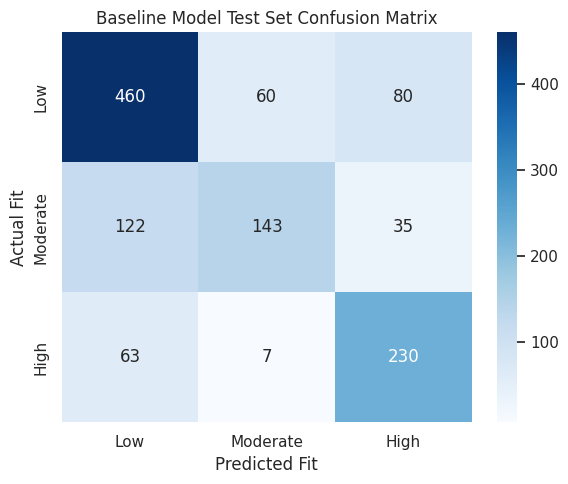

In [ ]:
#Holdout Test Evaluation & Confusion Matrix
y_pred_test = clf.predict(X_test)

test_acc = accuracy_score(y_test, y_pred_test)
test_f1 = f1_score(y_test, y_pred_test, average="macro")

print(f"Holdout Test Accuracy: {test_acc:.4f}")
print(f"Holdout Test Macro F1-Score: {test_f1:.4f}\n")

# Confusion Matrix Plot
cm = confusion_matrix(y_test, y_pred_test)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Low", "Moderate", "High"], yticklabels=["Low", "Moderate", "High"])
plt.title("Baseline Model Test Set Confusion Matrix")
plt.xlabel("Predicted Fit")
plt.ylabel("Actual Fit")
plt.tight_layout()
plt.show()

3.2 Stage 2: Dense Semantic Bi-Encoder (Sentence-BERT)
*  Pretrained Model: sentence-transformers/all-MiniLM-L6-v2.
*  Mechanism: Encodes text into 384-dimensional embeddings. Compute dense cosine similarity:

4.Deep Learning Classifier & Embedding Pipeline:
*  Pre-compute Sentence-BERT embeddings (all-MiniLM-L6-v2) for all pairs.
*  Build dual-branch TensorFlow/Keras neural network incorporating embedding interactions.
*  Fine-tune hyperparameters (learning rate, dropout rate, hidden layer dimensions).
*  Export trained weights to artifacts/fit_classifier.h5.

In [ ]:
#Environment Setup & Dependencies
import os
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
from sentence_transformers import SentenceTransformer, util
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

# Set seed for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
os.makedirs("../artifacts", exist_ok=True)

print(f"TensorFlow Version: {tf.__version__}")
print("GPUT Availability:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.21.0
GPUT Availability: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### How to Access and Enable GPU for TensorFlow in Google Colab

Google Colab provides free access to hardware accelerators like GPUs (Graphics Processing Units). Since your current environment shows `GPUT Availability: []`, follow these steps to enable the GPU:

#### 1. Enable GPU in Colab Settings:
1. In the top-right menu bar, click on **Runtime** (or look at the toolbar on top).
2. Select **Change runtime type**.
3. Under **Hardware accelerator**, select **T4 GPU** (or any other available GPU option like V100/A100 if you have Colab Pro).
4. Click **Save**.

*Note: This will restart your runtime session, meaning you will need to re-run your import and variable initialization cells.*

#### 2. Programmatic Verification Code:
Once the runtime has reconnected with a GPU, you can verify TensorFlow can access it using the code below:

In [ ]:
import tensorflow as tf

# Check if any GPU is detected by TensorFlow
gpus = tf.config.list_physical_devices('GPU')

if gpus:
    print(f"GPU is Available! detected GPUs: {len(gpus)}")
    for i, gpu in enumerate(gpus):
        print(f"  GPU {i}: {gpu}")
    # Display GPU details
    !nvidia-smi
else:
    print("No GPU detected. Please go to Runtime -> Change runtime type -> Hardware accelerator -> T4 GPU.")

GPU is Available! detected GPUs: 1
  GPU 0: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Sun Nov  8 08:26:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8              9W /   70W |       3MiB /  15360MiB |      0%      Default |
|                              

In [ ]:
# Cell 3: Dense Feature Extraction via Sentence-BERT (Bi-Encoder)
MODEL_NAME = "all-MiniLM-L6-v2"
print(f"Loading pretrained Sentence-BERT model: {MODEL_NAME}")
sbert_model = SentenceTransformer(MODEL_NAME)

def generate_sbert_embeddings(df_subset: pd.DataFrame):
    """Generates 384-dimensional dense vectors and cosine similarity scores."""
    res_embeddings = sbert_model.encode(
        df_subset["clean_resume"].tolist(),
        show_progress_bar=True,
        convert_to_numpy=True
    )
    jd_embeddings = sbert_model.encode(
        df_subset["clean_jd"].tolist(),
        show_progress_bar=True,
        convert_to_numpy=True
    )

    # Compute normalized pair-wise cosine similarity
    res_norm = res_embeddings / (np.linalg.norm(res_embeddings, axis=1, keepdims=True) + 1e-9)
    jd_norm = jd_embeddings / (np.linalg.norm(jd_embeddings, axis=1, keepdims=True) + 1e-9)
    cosine_sims = np.sum(res_norm * jd_norm, axis=1, keepdims=True)

    return res_embeddings, jd_embeddings, cosine_sims

print("\nEncoding Training Pairs...")
X_train_res, X_train_jd, sim_train = generate_sbert_embeddings(train_df)

print("\nEncoding Validation Pairs...")
X_val_res, X_val_jd, sim_val = generate_sbert_embeddings(val_df)

print("\nEncoding Holdout Test Pairs...")
X_test_res, X_test_jd, sim_test = generate_sbert_embeddings(test_df)

y_train = train_df["target"].values
y_val = val_df["target"].values
y_test = test_df["target"].values

Loading pretrained Sentence-BERT model: all-MiniLM-L6-v2


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (13 outputs left out)

Batches:   0%|          | 0/38 [00:00<?, ?it/s]


Encoding Holdout Test Pairs...


Batches:   0%|          | 0/38 [00:00<?, ?it/s]

Batches:   0%|          | 0/38 [00:00<?, ?it/s]

In [ ]:
# Cell 4: TensorFlow/Keras Deep Neural Network Architecture

def build_fit_classifier(embedding_dim: int = 384) -> tf.keras.Model:
    resume_input = layers.Input(shape=(embedding_dim,), name="resume_embedding")
    jd_input = layers.Input(shape=(embedding_dim,), name="jd_embedding")
    sim_input = layers.Input(shape=(1,), name="cosine_similarity")

    # Bytecode-free |resume_embedding - jd_embedding|
    diff = layers.Subtract()([resume_input, jd_input])
    neg_diff = layers.Rescaling(-1.0)(diff)
    abs_diff = layers.Maximum()([diff, neg_diff])

    # Element-wise product
    mult = layers.Multiply()([resume_input, jd_input])

    x = layers.Concatenate()([resume_input, jd_input, abs_diff, mult, sim_input])

    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.2)(x)

    output = layers.Dense(3, activation="softmax", name="fit_category")(x)

    model = models.Model(
        inputs={
            "resume_embedding": resume_input,
            "jd_embedding": jd_input,
            "cosine_similarity": sim_input,
        },
        outputs=output,
    )
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model

#model = build_multi_input_fit_classifier(embedding_dim=384)
model = build_fit_classifier(embedding_dim=384)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ resume_embedding    │ (None, 384)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ jd_embedding        │ (None, 384)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ subtract (Subtract) │ (None, 384)       │          0 │ resume_embedding… │
│                     │                   │            │ jd_embedding[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 384)       │          0 │ subtract[0][0]    │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ maximum (Maximum)   │ (None, 384)       │          0 │ subtract[0][0],   │
│                     │                   │            │ rescaling[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply (Multiply) │ (None, 384)       │          0 │ resume_embedding… │
│                     │                   │            │ jd_embedding[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cosine_similarity   │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 1537)      │          0 │ resume_embedding… │
│ (Concatenate)       │                   │            │ jd_embedding[0][… │
│                     │                   │            │ maximum[0][0],    │
│                     │                   │            │ multiply[0][0],   │
│                     │                   │            │ cosine_similarit… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    393,728 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 256)       │      1,024 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │     16,448 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ fit_category        │ (None, 3)         │        195 │ dropout_1[0][0]   │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 411,395 (1.57 MB)

 Trainable params: 410,883 (1.57 MB)

 Non-trainable params: 512 (2.00 KB)

In [ ]:
# Cell 5: Model Training with Callbacks
artifact_path = "../artifacts/fit_classifier.keras"

model_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        filepath=artifact_path,
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

train_inputs = {"resume_embedding": X_train_res, "jd_embedding": X_train_jd, "cosine_similarity": sim_train}
val_inputs = {"resume_embedding": X_val_res, "jd_embedding": X_val_jd, "cosine_similarity": sim_val}

print("Training SBERT-Keras Fit Classifier...")
history = model.fit(
    train_inputs,
    y_train,
    validation_data=(val_inputs, y_val),
    epochs=40,
    batch_size=32,
    callbacks=model_callbacks,
    verbose=1
)

Training SBERT-Keras Fit Classifier...
Epoch 1/40
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3771 - loss: 1.1656
Epoch 1: val_accuracy improved from None to 0.50417, saving model to ../artifacts/fit_classifier.keras

Epoch 1: finished saving model to ../artifacts/fit_classifier.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.4248 - loss: 1.0996 - val_accuracy: 0.5042 - val_loss: 1.0481 - learning_rate: 1.0000e-04
Epoch 2/40
173/175 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5566 - loss: 0.9335
Epoch 2: val_accuracy improved from 0.50417 to 0.55917, saving model to ../artifacts/fit_classifier.keras

Epoch 2: finished saving model to ../artifacts/fit_classifier.keras
175/175 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5584 - loss: 0.9217 - val_accuracy: 0.5592 - val_loss: 0.9752 - learning_rate: 1.0000e-04
Epoch 3/40
175/175 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6031 - loss: 0.8408
Epoch 3: val_accuracy improved from 0.55917 to 0.61083, saving mo

38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
SBERT-Keras Validation Accuracy: 0.7375
SBERT-Keras Validation Macro F1-Score: 0.7211



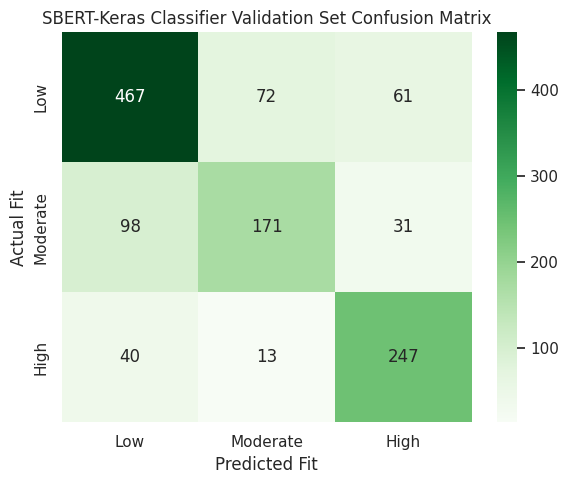

In [ ]:
# Predict probabilities on validation dataset
val_preds_prob = model.predict(val_inputs)
# Map probabilities to class predictions (0, 1, or 2)
val_preds = np.argmax(val_preds_prob, axis=1)

# Compute validation accuracy and macro F1-score
sbert_val_acc = accuracy_score(y_val, val_preds)
sbert_val_f1 = f1_score(y_val, val_preds, average='macro')
print(f"SBERT-Keras Validation Accuracy: {sbert_val_acc:.4f}")
print(f"SBERT-Keras Validation Macro F1-Score: {sbert_val_f1:.4f}\n")

# Calculate and plot the Confusion Matrix
cm_val = confusion_matrix(y_val, val_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_val,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Low", "Moderate", "High"],
    yticklabels=["Low", "Moderate", "High"]
)
plt.title("SBERT-Keras Classifier Validation Set Confusion Matrix")
plt.xlabel("Predicted Fit")
plt.ylabel("Actual Fit")
plt.tight_layout()
plt.show()

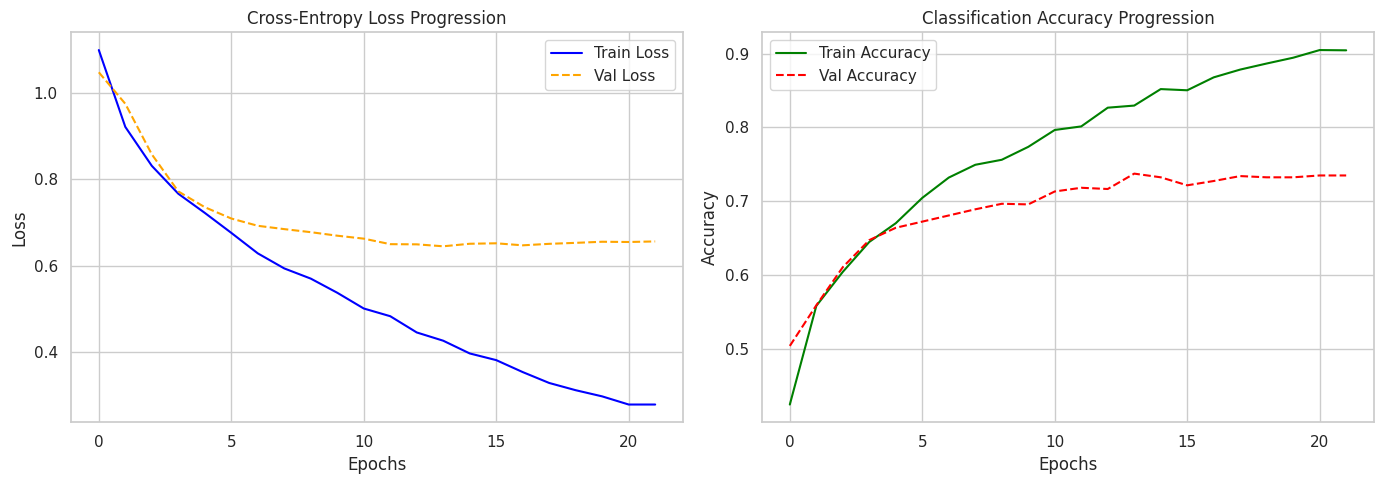

In [ ]:
# Visualizing Training Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss Plot
ax1.plot(history.history["loss"], label="Train Loss", color="blue")
ax1.plot(history.history["val_loss"], label="Val Loss", color="orange", linestyle="--")
ax1.set_title("Cross-Entropy Loss Progression")
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Loss")
ax1.legend()

# Accuracy Plot
ax2.plot(history.history["accuracy"], label="Train Accuracy", color="green")
ax2.plot(history.history["val_accuracy"], label="Val Accuracy", color="red", linestyle="--")
ax2.set_title("Classification Accuracy Progression")
ax2.set_xlabel("Epochs")
ax2.set_ylabel("Accuracy")
ax2.legend()

plt.tight_layout()
plt.show()

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
SBERT-Keras Holdout Test Accuracy: 0.7158
SBERT-Keras Holdout Test Macro F1-Score: 0.6991



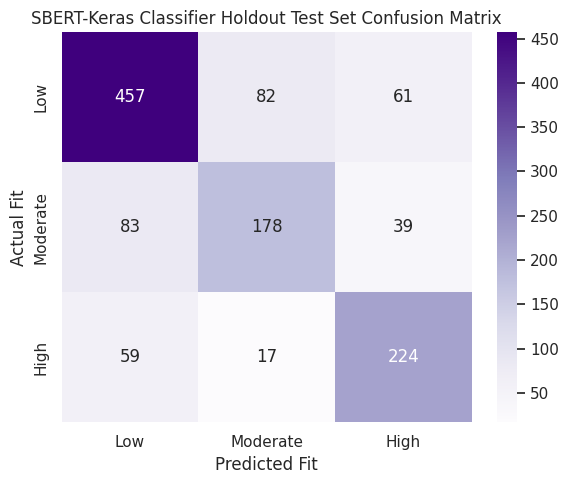

In [ ]:
# Map the holdout test set inputs
test_inputs = {
    "resume_embedding": X_test_res,
    "jd_embedding": X_test_jd,
    "cosine_similarity": sim_test
}

# Predict probabilities on holdout test dataset
test_preds_prob = model.predict(test_inputs)
# Map probabilities to class predictions (0, 1, or 2)
test_preds = np.argmax(test_preds_prob, axis=1)

# Compute holdout test accuracy and macro F1-score
sbert_test_acc = accuracy_score(y_test, test_preds)
sbert_test_f1 = f1_score(y_test, test_preds, average='macro')
print(f"SBERT-Keras Holdout Test Accuracy: {sbert_test_acc:.4f}")
print(f"SBERT-Keras Holdout Test Macro F1-Score: {sbert_test_f1:.4f}\n")

# Calculate and plot the Confusion Matrix for the Holdout Test Set
cm_test = confusion_matrix(y_test, test_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Low", "Moderate", "High"],
    yticklabels=["Low", "Moderate", "High"]
)
plt.title("SBERT-Keras Classifier Holdout Test Set Confusion Matrix")
plt.xlabel("Predicted Fit")
plt.ylabel("Actual Fit")
plt.tight_layout()
plt.show()

3.3 Stage 3: Fine-Tuned Classifier (TensorFlow / Keras)

A neural network takes vector representations along with distance metrics to predict multi-class fit output (Low, Moderate, High).

3.4 Stage 4: Explainable Skill-Gap Extraction Module

Extracts target skills from the JD using entity extraction and matches them against candidate resume phrases using embedding distance.

In [ ]:
import spacy
from sentence_transformers import SentenceTransformer, util

nlp = spacy.load("en_core_web_sm")
sbert_model = SentenceTransformer('all-MiniLM-L6-v2')

def extract_skill_gaps(resume_text: str, jd_text: str, similarity_threshold: float = 0.65):
    # Extract noun chunks/entities as candidate skills from JD
    jd_doc = nlp(jd_text)
    jd_keywords = list(set([chunk.text.lower() for chunk in jd_doc.noun_chunks if len(chunk.text.split()) <= 3]))

    resume_doc = nlp(resume_text)
    resume_keywords = list(set([chunk.text.lower() for chunk in resume_doc.noun_chunks if len(chunk.text.split()) <= 3]))

    if not jd_keywords or not resume_keywords:
        return {"matched_skills": [], "missing_skills": jd_keywords}

    jd_embs = sbert_model.encode(jd_keywords, convert_to_tensor=True)
    res_embs = sbert_model.encode(resume_keywords, convert_to_tensor=True)

    sim_matrix = util.cos_sim(jd_embs, res_embs)

    matched_skills = []
    missing_skills = []

    for idx, jd_kw in enumerate(jd_keywords):
        max_sim = float(sim_matrix[idx].max())
        if max_sim >= similarity_threshold:
            matched_skills.append({"skill": jd_kw, "score": round(max_sim, 2)})
        else:
            missing_skills.append({"skill": jd_kw, "score": round(max_sim, 2)})

    return {"matched_skills": matched_skills, "missing_skills": missing_skills}



Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]